# Proyek Analisis Data: [E-commerce-public-dataset]
- **Nama:** [Fatur Rachman Putra Nanta Efendi]
- **Email:** [ds296b6y0595@student.devacademy.id]
- **ID Dicoding:** [ds296b6y0595]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perkembangan jumlah pesanan (order) per bulan pada dataset E-Commerce Public selama **4 September 2016 sampai 17 Oktober 2018**, dan pada bulan apa jumlah pesanan mencapai nilai tertinggi? Analisis ini digunakan untuk mengidentifikasi pola permintaan bulanan sebagai dasar perencanaan operasional.
- **Pertanyaan 2:** Bagaimana distribusi jumlah transaksi berdasarkan metode pembayaran (`payment_type`) pada pesanan yang tercatat selama **4 September 2016 sampai 17 Oktober 2018**, dan metode pembayaran apa yang paling dominan? Hasilnya dapat menjadi dasar untuk memprioritaskan kemudahan dan dukungan metode pembayaran.

*Rentang waktu ditentukan dari nilai minimum dan maksimum `order_purchase_timestamp` pada dataset. Bulan September 2018 dan Oktober 2018 merupakan periode parsial dalam dataset sehingga tidak dibandingkan sebagai bulan penuh.*

## Import Semua Packages/Library yang Digunakan

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile

## Data Wrangling

### Gathering Data

#### Load df ...

In [5]:
# Mengatur path dataset
zip_path = '/content/E-commerce-public-dataset.zip'
extract_path = '/content/e-commerce-data'

# Mengekstrak dataset
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# Mencari lokasi file CSV secara otomatis
csv_files = {}

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.endswith('.csv'):
            csv_files[file] = os.path.join(root, file)

# Menampilkan daftar file CSV
for file in csv_files:
    print(file)


# Load dataset ke dalam DataFrame

orders_df = pd.read_csv(csv_files['orders_dataset.csv'])
order_items_df = pd.read_csv(csv_files['order_items_dataset.csv'])
order_payments_df = pd.read_csv(csv_files['order_payments_dataset.csv'])
order_reviews_df = pd.read_csv(csv_files['order_reviews_dataset.csv'])
customers_df = pd.read_csv(csv_files['customers_dataset.csv'])
products_df = pd.read_csv(csv_files['products_dataset.csv'])
product_category_name_translation_df = pd.read_csv(
    csv_files['product_category_name_translation.csv']
)
sellers_df = pd.read_csv(csv_files['sellers_dataset.csv'])
geolocation_df = pd.read_csv(csv_files['geolocation_dataset.csv'])

# Menampilkan data pesanan
orders_df.head()



products_dataset.csv
sellers_dataset.csv
customers_dataset.csv
orders_dataset.csv
order_reviews_dataset.csv
product_category_name_translation.csv
order_items_dataset.csv
order_payments_dataset.csv
geolocation_dataset.csv


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:** (Opsional)
- Dataset berhasil dimuat ke dalam DataFrame dan menampilkan 5 data pesanan pertama.
- Data pesanan memiliki beberapa atribut penting, seperti order_status, order_purchase_timestamp, order_approved_at, dan tanggal pengiriman.
- Kelima data pesanan yang ditampilkan memiliki status delivered, yang menunjukkan bahwa pesanan telah berhasil dikirim kepada pelanggan.
- Kolom timestamp dapat digunakan untuk analisis lebih lanjut terkait tren pemesanan dan waktu pengiriman.
- Data yang ditampilkan masih berupa sampel 5 baris pertama sehingga belum dapat menggambarkan keseluruhan dataset.

### Assessing Data

#### Identifying ... problem

In [6]:

# Daftar seluruh DataFrame
dataframes = {
    'orders': orders_df,
    'order_items': order_items_df,
    'order_payments': order_payments_df,
    'order_reviews': order_reviews_df,
    'customers': customers_df,
    'products': products_df,
    'product_category_name_translation': product_category_name_translation_df,
    'sellers': sellers_df,
    'geolocation': geolocation_df
}

# Memeriksa jumlah baris dan kolom
for name, df in dataframes.items():
    print(f"\n{name}")
    print(f"Jumlah baris: {df.shape[0]}")
    print(f"Jumlah kolom: {df.shape[1]}")


# Memeriksa missing value dan duplicate data
for name, df in dataframes.items():
    print(f"\n===== {name} =====")

    print("Missing Value:")
    print(df.isnull().sum()[df.isnull().sum() > 0])

    print(f"\nJumlah Duplicate: {df.duplicated().sum()}")


# Memeriksa tipe data setiap DataFrame
for name, df in dataframes.items():
    print(f"\n===== {name} =====")
    print(df.info())




orders
Jumlah baris: 99441
Jumlah kolom: 8

order_items
Jumlah baris: 112650
Jumlah kolom: 7

order_payments
Jumlah baris: 103886
Jumlah kolom: 5

order_reviews
Jumlah baris: 99224
Jumlah kolom: 7

customers
Jumlah baris: 99441
Jumlah kolom: 5

products
Jumlah baris: 32951
Jumlah kolom: 9

product_category_name_translation
Jumlah baris: 71
Jumlah kolom: 2

sellers
Jumlah baris: 3095
Jumlah kolom: 4

geolocation
Jumlah baris: 1000163
Jumlah kolom: 5

===== orders =====
Missing Value:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

Jumlah Duplicate: 0

===== order_items =====
Missing Value:
Series([], dtype: int64)

Jumlah Duplicate: 0

===== order_payments =====
Missing Value:
Series([], dtype: int64)

Jumlah Duplicate: 0

===== order_reviews =====
Missing Value:
review_comment_title      87656
review_comment_message    58247
dtype: int64

Jumlah Duplicate: 0

===== customers =====
Missing Value:
Series([],

**Steps to Take:**

- Menghapus data duplikat pada geolocation_df menggunakan drop_duplicates() untuk menghindari redundansi data lokasi.
- Mempertahankan missing value pada kolom tanggal di orders_df karena dapat berkaitan dengan status pesanan yang belum disetujui, dibatalkan, atau belum dikirim.
- Mempertahankan missing value pada kolom komentar ulasan di order_reviews_df karena komentar bersifat opsional.
- Menangani missing value pada products_df dengan mengisi kolom kategorikal menggunakan label 'Unknown' dan kolom numerik menggunakan nilai median agar data produk tetap dapat digunakan dalam analisis.


**Insight:** (Opsional)

- Dataset geolocation memiliki 261.831 data duplikat yang perlu dibersihkan agar tidak menimbulkan redundansi dalam analisis geografis.
- Missing value ditemukan pada dataset orders, order_reviews, dan products. Penanganan missing value dilakukan berdasarkan karakteristik masing-masing kolom agar informasi penting tetap terjaga.
- Dataset lainnya tidak menunjukkan missing value dan duplicate data pada pemeriksaan yang dilakukan.

### Cleaning Data

#### Fixing ... problem

In [7]:
# Mengubah kolom timestamp menjadi datetime agar dapat diperiksa secara konsisten
timestamp_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for column in timestamp_columns:
    orders_df[column] = pd.to_datetime(orders_df[column], errors='coerce')

# Missing timestamp tidak diisi dengan modus karena tanggal buatan dapat
# mengubah informasi proses pesanan. Nilai kosong dipertahankan dan
# ditangani sesuai kebutuhan analisis.
# Kolom komentar ulasan bersifat opsional; gunakan label agar tidak kosong.
order_reviews_df['review_comment_title'] = order_reviews_df['review_comment_title'].fillna('No Title')
order_reviews_df['review_comment_message'] = order_reviews_df['review_comment_message'].fillna('No Comment')

# Missing value pada atribut produk: kategorikal diberi label Unknown,
# sedangkan atribut numerik diisi median untuk menjaga baris tetap tersedia.
products_df['product_category_name'] = products_df['product_category_name'].fillna('Unknown')

numeric_product_columns = [
    'product_name_lenght',
    'product_description_lenght',
    'product_photos_qty',
    'product_weight_g',
    'product_length_cm',
    'product_height_cm',
    'product_width_cm'
]

for column in numeric_product_columns:
    products_df[column] = products_df[column].fillna(products_df[column].median())

# Menghapus baris duplikat pada geolocation agar tidak redundan
geolocation_df = geolocation_df.drop_duplicates().copy()

# Memeriksa kembali missing value setelah penanganan
for name, df in dataframes.items():
    print(f"===== {name} =====")
    print(df.isnull().sum())
    print()


===== orders =====
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

===== order_items =====
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

===== order_payments =====
order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

===== order_reviews =====
review_id                  0
order_id                   0
review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64

===== customers =====
customer_id   

**Insight:**

- Missing value pada timestamp pesanan dipertahankan, bukan diisi dengan tanggal modus, karena nilai kosong dapat merepresentasikan tahapan pesanan yang belum terjadi atau tidak tercatat.
- Kolom komentar ulasan yang kosong diisi label `No Title` dan `No Comment` karena komentar bersifat opsional.
- Missing value pada kategori produk ditandai `Unknown`, sedangkan atribut numerik produk diisi dengan median kolom masing-masing.
- Data duplikat pada `geolocation_df` dihapus untuk mengurangi redundansi.
- Penanganan dilakukan sesuai karakteristik tiap kolom. Oleh karena itu, tidak semua dataset harus menjadi bebas missing value; nilai kosong yang masih ada pada timestamp tetap dipertahankan secara sengaja.

## Exploratory Data Analysis (EDA)

### Eksplorasi Karakteristik Data

Pada tahap EDA, data dieksplorasi untuk memahami distribusi status pesanan, metode pembayaran, nilai pembayaran, dan pola temporal. Eksplorasi ini menjadi dasar untuk menjawab pertanyaan bisnis yang telah ditentukan.

In [8]:
# Statistik deskriptif data pesanan
display(orders_df.describe(include='all').transpose())

# Frekuensi dan proporsi status pesanan
status_counts = orders_df['order_status'].value_counts()
status_proportion = orders_df['order_status'].value_counts(normalize=True).mul(100).round(2)

status_summary = pd.DataFrame({
    'Jumlah': status_counts,
    'Proporsi (%)': status_proportion
})
display(status_summary)

# Frekuensi dan proporsi metode pembayaran
payment_counts = order_payments_df['payment_type'].value_counts()
payment_proportion = order_payments_df['payment_type'].value_counts(normalize=True).mul(100).round(2)

payment_summary = pd.DataFrame({
    'Jumlah transaksi pembayaran': payment_counts,
    'Proporsi (%)': payment_proportion
})
display(payment_summary)

# Statistik deskriptif nilai pembayaran
display(order_payments_df['payment_value'].describe())

,count,unique,top,freq,mean,min,25%,50%,75%,max
order_id,99441,99441,e481f51cbdc54678b7cc49136f2d6af7,1,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,99441,99441,9ef432eb6251297304e76186b10a928d,1,NaN,NaN,NaN,NaN,NaN,NaN
order_status,99441,8,delivered,96478,NaN,NaN,NaN,NaN,NaN,NaN
order_purchase_timestamp,99441,NaN,NaN,NaN,2017-12-31 08:43:12.776581120,2016-09-04 21:15:19,2017-09-12 14:46:19,2018-01-18 23:04:36,2018-05-04 15:42:16,2018-10-17 17:30:18
order_approved_at,99281,NaN,NaN,NaN,2017-12-31 18:35:24.098800128,2016-09-15 12:16:38,2017-09-12 23:24:16,2018-01-19 11:36:13,2018-05-04 20:35:10,2018-09-03 17:40:06
order_delivered_carrier_date,97658,NaN,NaN,NaN,2018-01-04 21:49:48.138278656,2016-10-08 10:34:01,2017-09-15 22:28:50.249999872,2018-01-24 16:10:58,2018-05-08 13:37:45,2018-09-11 19:48:28
order_delivered_customer_date,96476,NaN,NaN,NaN,2018-01-14 12:09:19.035542272,2016-10-11 13:46:32,2017-09-25 22:07:22.249999872,2018-02-02 19:28:10.500000,2018-05-15 22:48:52.249999872,2018-10-17 13:22:46
order_estimated_delivery_date,99441,NaN,NaN,NaN,2018-01-24 03:08:37.730111232,2016-09-30 00:00:00,2017-10-03 00:00:00,2018-02-15 00:00:00,2018-05-25 00:00:00,2018-11-12 00:00:00


,Jumlah,Proporsi (%)
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


,Jumlah transaksi pembayaran,Proporsi (%)
payment_type,,
credit_card,76795,73.92
boleto,19784,19.04
voucher,5775,5.56
debit_card,1529,1.47
not_defined,3,0.00


,payment_value
count,103886.000000
mean,154.100380
std,217.494064
min,0.000000
25%,56.790000
50%,100.000000
75%,171.837500
max,13664.080000


**Insight:**

- Status `delivered` merupakan status pesanan yang paling banyak ditemukan. Status-status lainnya seperti `shipped`, `canceled`, dan `unavailable` memiliki frekuensi yang jauh lebih kecil.
- `credit_card` menjadi metode pembayaran dengan frekuensi tertinggi, diikuti oleh `boleto`. Persentase tiap metode ditampilkan pada tabel agar perbandingan tidak hanya bergantung pada jumlah absolut.
- Nilai pembayaran memiliki rentang yang lebar dan terdapat nilai maksimum yang jauh lebih tinggi daripada median. Distribusi nilai transaksi perlu dilihat melalui histogram dan boxplot sebelum membuat kesimpulan tentang transaksi tipikal.
- Hasil frekuensi dan statistik ini menjadi konteks untuk analisis visualisasi pada bagian berikutnya.

### EDA Univariate: Distribusi Nilai Pembayaran

Histogram membantu melihat bentuk distribusi nilai pembayaran, sedangkan boxplot membantu mendeteksi nilai ekstrem. Nilai ekstrem tidak otomatis dianggap salah; perlu dipertimbangkan sebagai transaksi bernilai tinggi yang mungkin valid.

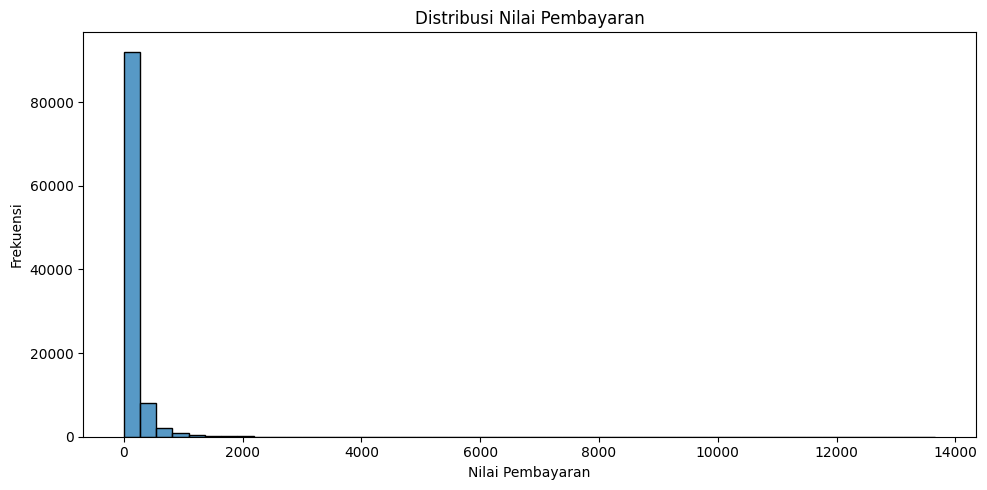

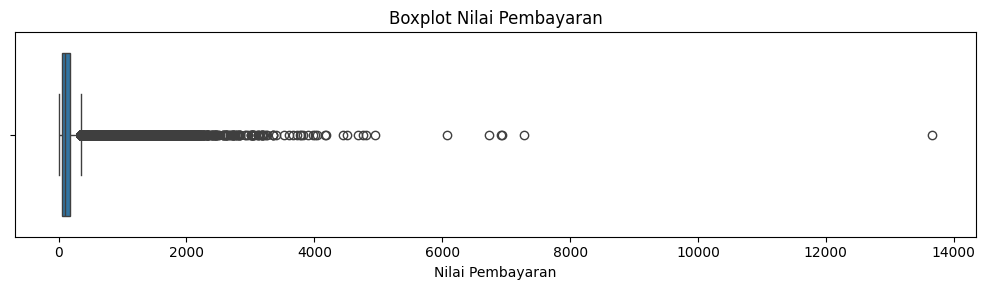

Median nilai pembayaran: 100.00
Nilai pembayaran maksimum: 13664.08
Interpretasi: bandingkan median dengan nilai maksimum untuk menilai indikasi nilai ekstrem.


In [9]:
# Histogram nilai pembayaran
plt.figure(figsize=(10, 5))
sns.histplot(data=order_payments_df, x='payment_value', bins=50)
plt.title('Distribusi Nilai Pembayaran')
plt.xlabel('Nilai Pembayaran')
plt.ylabel('Frekuensi')
plt.tight_layout()
plt.show()

# Boxplot nilai pembayaran
plt.figure(figsize=(10, 3))
sns.boxplot(data=order_payments_df, x='payment_value')
plt.title('Boxplot Nilai Pembayaran')
plt.xlabel('Nilai Pembayaran')
plt.tight_layout()
plt.show()

payment_value_stats = order_payments_df['payment_value'].describe()
print(f"Median nilai pembayaran: {payment_value_stats['50%']:.2f}")
print(f"Nilai pembayaran maksimum: {payment_value_stats['max']:.2f}")
print("Interpretasi: bandingkan median dengan nilai maksimum untuk menilai indikasi nilai ekstrem.")

### EDA Kategorikal: Status Pesanan

Bar chart berikut memperlihatkan jumlah dan proporsi setiap status pesanan untuk memahami kondisi pemenuhan pesanan.

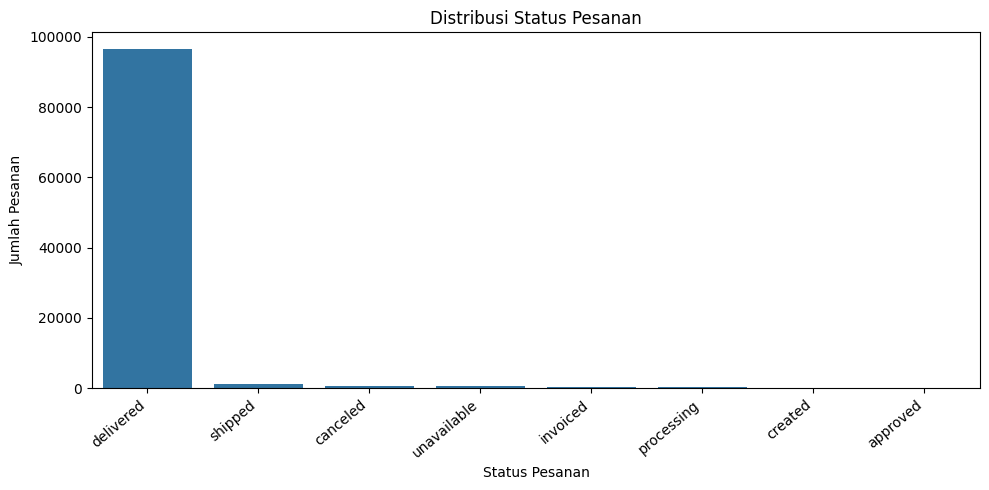

,Jumlah Pesanan,Proporsi (%)
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


Insight: status pesanan terbanyak adalah 'delivered' sebanyak 96,478 pesanan.


In [10]:
status_counts = orders_df['order_status'].value_counts()

plt.figure(figsize=(10, 5))
sns.barplot(x=status_counts.index, y=status_counts.values)
plt.title('Distribusi Status Pesanan')
plt.xlabel('Status Pesanan')
plt.ylabel('Jumlah Pesanan')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    'Jumlah Pesanan': status_counts,
    'Proporsi (%)': (orders_df['order_status'].value_counts(normalize=True) * 100).round(2)
}))

most_common_status = status_counts.idxmax()
print(f"Insight: status pesanan terbanyak adalah '{most_common_status}' sebanyak {status_counts.max():,} pesanan.")

### EDA Bivariate: Jumlah Pesanan dan Total Pembayaran per Bulan

Data pesanan digabungkan dengan data pembayaran berdasarkan `order_id`, lalu diagregasi per bulan. Scatter plot digunakan untuk melihat apakah bulan dengan jumlah pesanan lebih tinggi juga cenderung memiliki total nilai pembayaran lebih tinggi. Perlu diingat bahwa satu pesanan dapat memiliki lebih dari satu catatan pembayaran.

,month,total_payment_value,order_count
20,2018-06,1023880.50,6167
21,2018-07,1066540.75,6292
22,2018-08,1022425.32,6512
23,2018-09,4439.54,16
24,2018-10,589.67,4


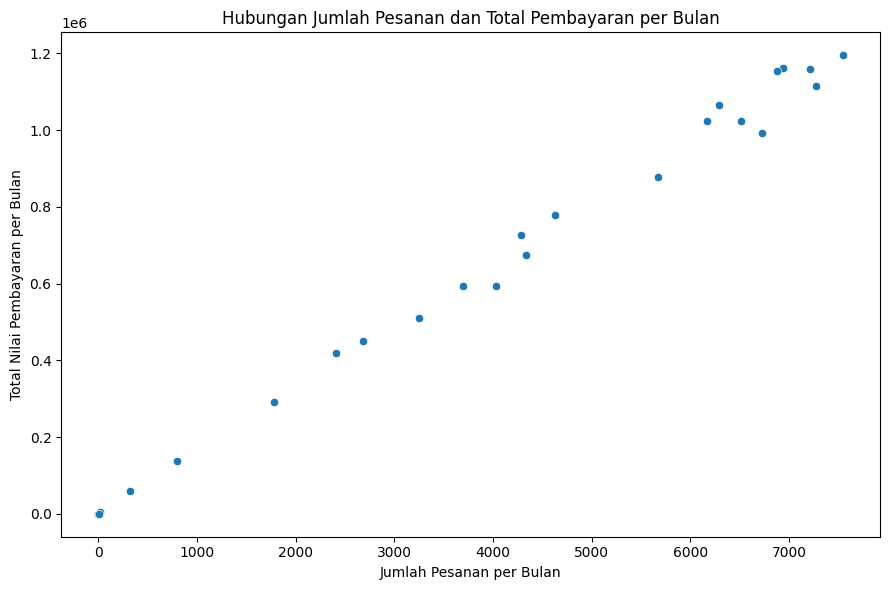

Korelasi Pearson antar agregat bulanan: 0.997
Interpretasi: korelasi menunjukkan hubungan pada tingkat agregat bulanan, bukan sebab-akibat.


In [11]:
# Konversi tanggal dan gabungkan data order dengan payment
orders_for_analysis = orders_df.copy()
orders_for_analysis['order_purchase_timestamp'] = pd.to_datetime(
    orders_for_analysis['order_purchase_timestamp'], errors='coerce'
)

orders_payments_analysis = orders_for_analysis[
    ['order_id', 'order_purchase_timestamp']
].merge(
    order_payments_df[['order_id', 'payment_value']],
    on='order_id',
    how='inner'
)

orders_payments_analysis = orders_payments_analysis.dropna(
    subset=['order_purchase_timestamp']
)
orders_payments_analysis['month'] = (
    orders_payments_analysis['order_purchase_timestamp'].dt.to_period('M')
)

monthly_business_metrics = orders_payments_analysis.groupby('month').agg(
    total_payment_value=('payment_value', 'sum'),
    order_count=('order_id', 'nunique')
).reset_index()

display(monthly_business_metrics.tail())

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=monthly_business_metrics,
    x='order_count',
    y='total_payment_value'
)
plt.title('Hubungan Jumlah Pesanan dan Total Pembayaran per Bulan')
plt.xlabel('Jumlah Pesanan per Bulan')
plt.ylabel('Total Nilai Pembayaran per Bulan')
plt.tight_layout()
plt.show()

correlation = monthly_business_metrics['order_count'].corr(
    monthly_business_metrics['total_payment_value']
)
print(f"Korelasi Pearson antar agregat bulanan: {correlation:.3f}")
print("Interpretasi: korelasi menunjukkan hubungan pada tingkat agregat bulanan, bukan sebab-akibat.")

## Visualization & Explanatory Analysis

### Pertanyaan Bisnis 1: Bagaimana perkembangan jumlah pesanan per bulan dari 4 September 2016 sampai 17 Oktober 2018, dan bulan mana yang memiliki jumlah pesanan tertinggi?

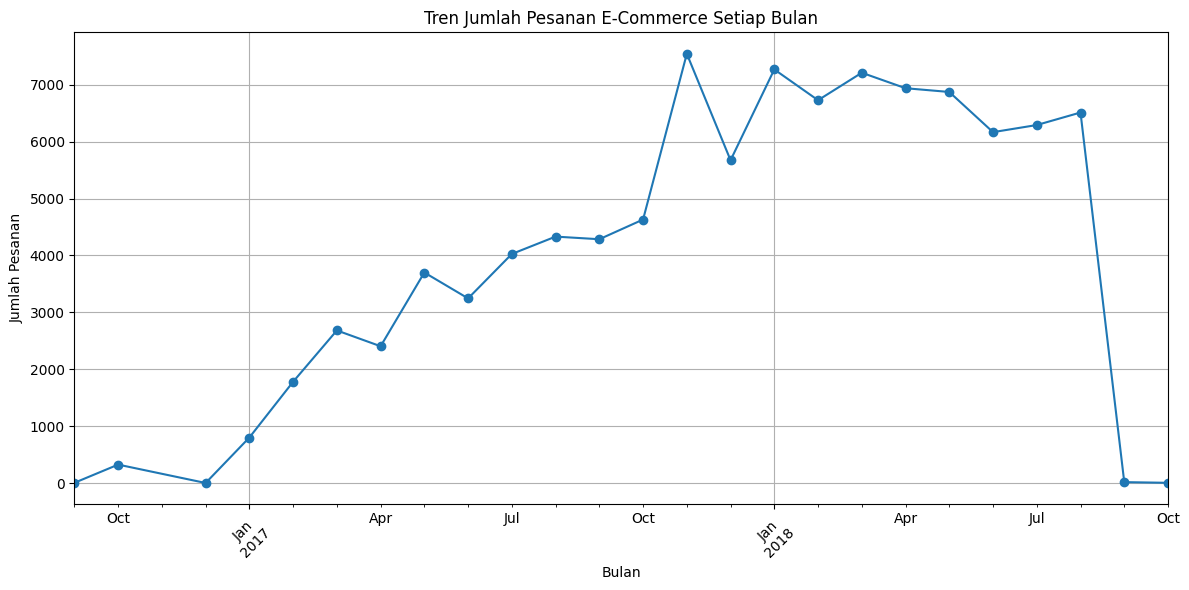

In [12]:

import matplotlib.pyplot as plt
import pandas as pd

# Mengubah kolom tanggal menjadi datetime
orders_df['order_purchase_timestamp'] = pd.to_datetime(
    orders_df['order_purchase_timestamp']
)

# Menghitung jumlah pesanan setiap bulan
monthly_orders = orders_df.groupby(
    orders_df['order_purchase_timestamp'].dt.to_period('M')
)['order_id'].nunique()

# Visualisasi tren jumlah pesanan
plt.figure(figsize=(12, 6))
monthly_orders.plot(kind='line', marker='o')

plt.title('Tren Jumlah Pesanan E-Commerce Setiap Bulan')
plt.xlabel('Bulan')
plt.ylabel('Jumlah Pesanan')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


### Pertanyaan Bisnis 2: Bagaimana distribusi transaksi berdasarkan metode pembayaran selama 4 September 2016 sampai 17 Oktober 2018, dan metode mana yang paling dominan?

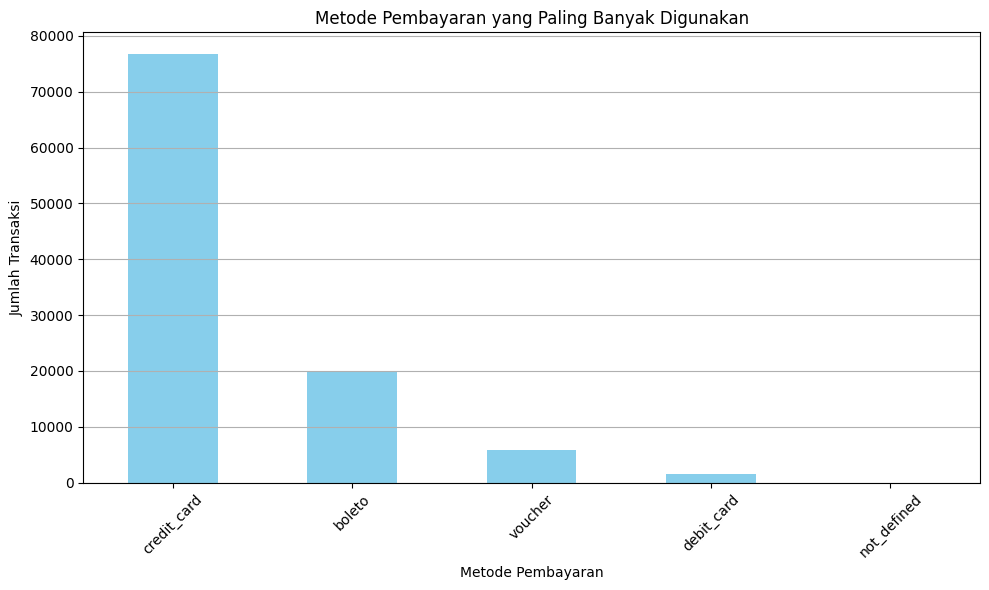

In [13]:

# Menghitung jumlah transaksi berdasarkan metode pembayaran
payment_counts = order_payments_df['payment_type'].value_counts()

# Visualisasi metode pembayaran
plt.figure(figsize=(10, 6))
payment_counts.plot(kind='bar', color='skyblue')

plt.title('Metode Pembayaran yang Paling Banyak Digunakan')
plt.xlabel('Metode Pembayaran')
plt.ylabel('Jumlah Transaksi')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()


**Insight:**

- Grafik menunjukkan perbandingan frekuensi transaksi pembayaran untuk setiap jenis `payment_type`.
- Berdasarkan perhitungan dataset, `credit_card` merupakan metode yang paling dominan dengan **76.795** catatan pembayaran; `boleto` berada di urutan kedua dengan **19.784** catatan.
- `voucher` tercatat sebanyak **5.775**, `debit_card` sebanyak **1.529**, dan `not_defined` sebanyak **3** catatan.
- Temuan ini menjawab Pertanyaan Bisnis 2: kartu kredit paling banyak digunakan pada data yang dianalisis. Jumlah tersebut adalah frekuensi catatan pembayaran, bukan jumlah pelanggan unik.

## Analisis Lanjutan (Opsional)

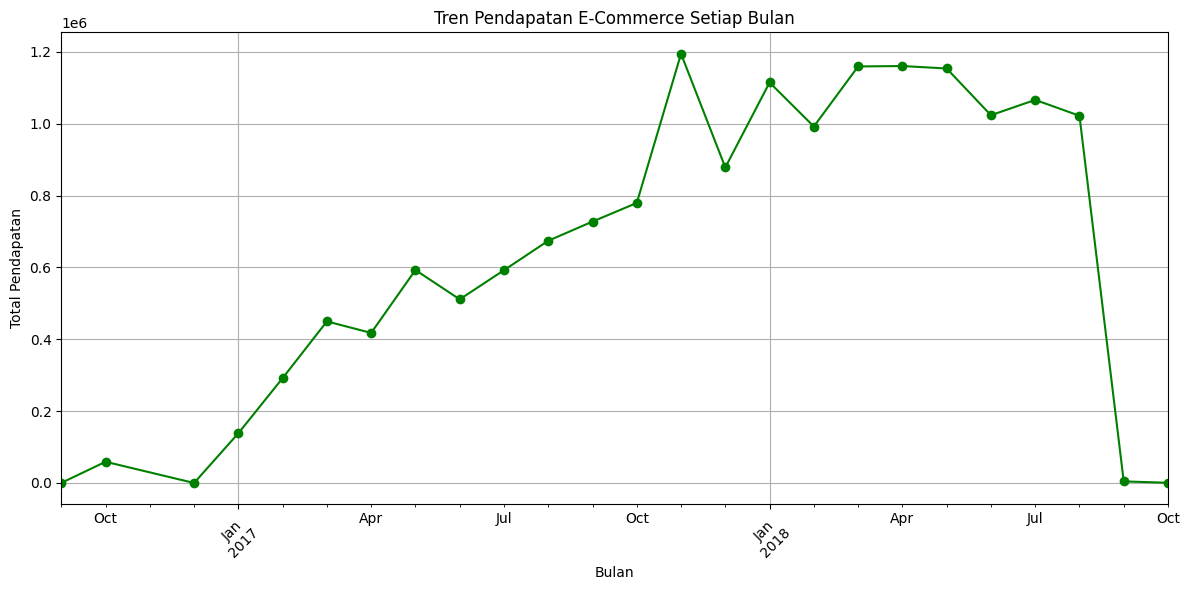

In [14]:

# Menggabungkan data orders dan order_payments
revenue_df = orders_df.merge(
    order_payments_df,
    on='order_id',
    how='inner'
)

# Menghitung total pendapatan setiap bulan
revenue_df['order_purchase_timestamp'] = pd.to_datetime(
    revenue_df['order_purchase_timestamp']
)

monthly_revenue = revenue_df.groupby(
    revenue_df['order_purchase_timestamp'].dt.to_period('M')
)['payment_value'].sum()

# Visualisasi tren pendapatan bulanan
plt.figure(figsize=(12, 6))
monthly_revenue.plot(kind='line', marker='o', color='green')

plt.title('Tren Pendapatan E-Commerce Setiap Bulan')
plt.xlabel('Bulan')
plt.ylabel('Total Pendapatan')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


**Insight:**

- Total nilai pembayaran bulanan menunjukkan pola yang umumnya meningkat pada periode 2017 hingga awal 2018, dengan fluktuasi antarbulan.
- Bulan November 2017 merupakan salah satu bulan dengan total pembayaran tertinggi dalam dataset.
- September 2018 dan Oktober 2018 memiliki jumlah pesanan yang sangat sedikit dibandingkan bulan-bulan sebelumnya. Dataset berakhir pada **17 Oktober 2018**, sehingga dua bulan terakhir merupakan periode parsial dan tidak tepat disimpulkan sebagai penurunan bisnis penuh.
- Scatter plot pada EDA bivariate membantu melihat keterkaitan antara jumlah pesanan bulanan dan total pembayaran bulanan. Hubungan tersebut tidak dapat diartikan sebagai sebab-akibat.

## Conclusion & Recommendation

- **Conclusion Pertanyaan Bisnis 1:** Jumlah pesanan bulanan berfluktuasi namun menunjukkan peningkatan yang kuat sepanjang periode lengkap yang tercakup dalam dataset. Bulan dengan jumlah pesanan tertinggi adalah **November 2017, sebanyak 7.544 pesanan**. September 2018 dan Oktober 2018 tidak dibandingkan sebagai bulan penuh karena data hanya mencakup sebagian bulan.
- **Conclusion Pertanyaan Bisnis 2:** Metode pembayaran yang paling dominan adalah **credit card**, dengan **76.795 catatan pembayaran**, diikuti oleh `boleto` sebanyak 19.784 catatan. Ini menunjukkan bahwa kartu kredit merupakan metode pembayaran yang paling sering tercatat dalam dataset. Frekuensi pembayaran tidak sama dengan jumlah pelanggan unik.

**Rekomendasi Action Item:**

- Menjaga proses pembayaran kartu kredit tetap mudah dan andal, serta tetap menyediakan metode alternatif seperti boleto dan voucher untuk menjangkau kebutuhan pelanggan yang beragam.
- Menggunakan tren jumlah pesanan bulanan sebagai salah satu masukan perencanaan kapasitas operasional, layanan pelanggan, dan pengiriman pada bulan dengan volume tinggi.
- Melakukan pemantauan data bulanan secara berkelanjutan. Saat membandingkan tren, pastikan periode yang dibandingkan sama-sama merupakan bulan penuh; hindari menyimpulkan penurunan dari September dan Oktober 2018 karena cakupan dataset berakhir pada 17 Oktober 2018.
- Meninjau transaksi dengan nilai pembayaran ekstrem secara terpisah untuk memastikan apakah transaksi tersebut valid dan memahami kontribusinya terhadap total pembayaran.